# CNN vs Vision Transformer (ViT)
This notebook demonstrates:
1. A side-by-side diagram showing how CNNs look locally vs how ViTs use global attention.
2. A mini exercise where students can change patch size and see how many tokens are created.
3. A toy dot-product attention demo showing how patches "talk" to each other.

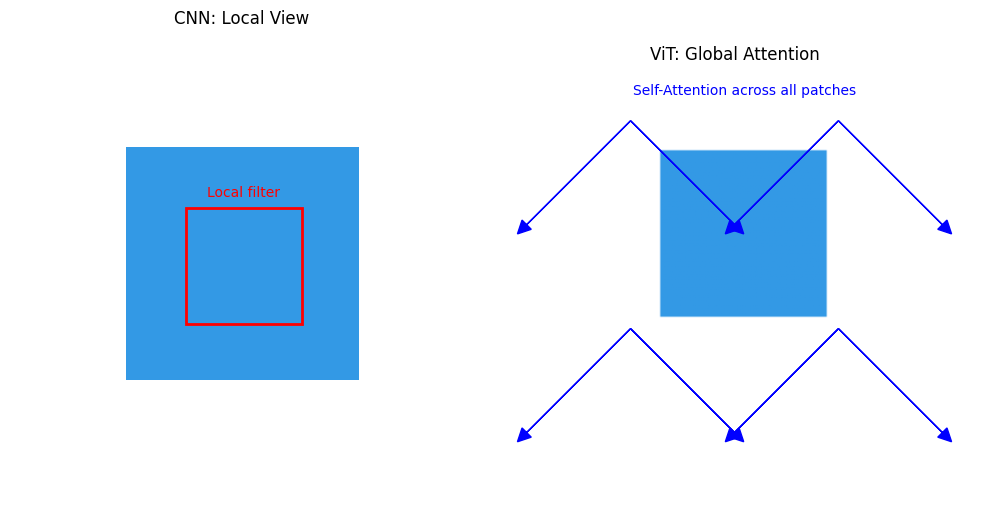

In [1]:
# Part 1: CNN vs ViT Visualization
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np

fig, ax = plt.subplots(1, 2, figsize=(10,5))

# Create a demo image
img = np.ones((128,128,3))
img[32:96,32:96] = [0.2, 0.6, 0.9]  # colored square

# --- Left: CNN Local View ---
ax[0].imshow(img)
ax[0].set_title("CNN: Local View")
ax[0].axis("off")
rect = patches.Rectangle((48,48),32,32,linewidth=2,edgecolor='red',facecolor='none')
ax[0].add_patch(rect)
ax[0].text(64, 45, "Local filter", color="red", ha="center")

# --- Right: ViT Global Attention ---
ax[1].imshow(img)
ax[1].set_title("ViT: Global Attention")
ax[1].axis("off")
for (x,y) in [(20,20),(100,20),(20,100),(100,100)]:
    ax[1].arrow(x,y,40,40,head_width=5,head_length=5,fc='blue',ec='blue')
    ax[1].arrow(x,y,-40,40,head_width=5,head_length=5,fc='blue',ec='blue')
ax[1].text(64, 10, "Self-Attention across all patches", color="blue", ha="center")
plt.tight_layout()
plt.show()

Patch size: 8x8 → Tokens: 256


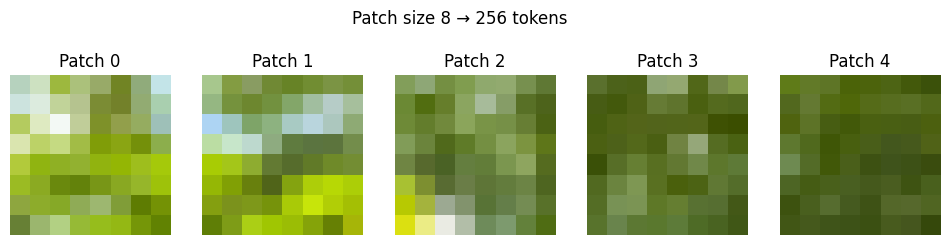

Patch size: 16x16 → Tokens: 64


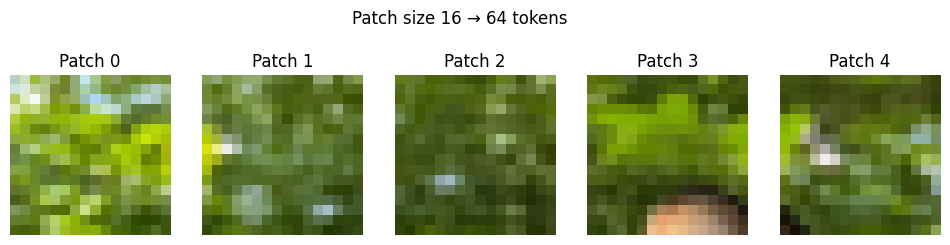

Patch size: 32x32 → Tokens: 16


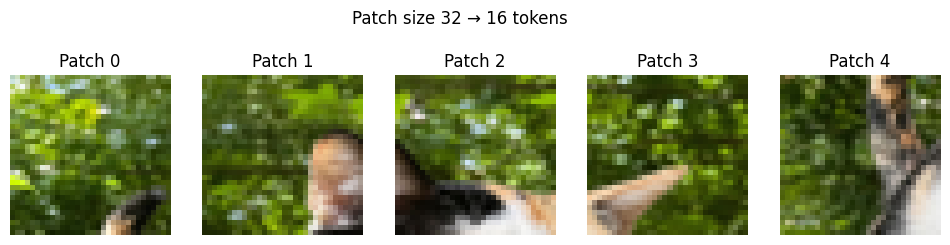

In [2]:
# Part 2: Mini Exercise – Changing Patch Size
from PIL import Image

img = Image.open("cat.jpg").resize((128,128))
img_array = np.array(img)

def split_into_patches(image, patch_size):
    patches = []
    for i in range(0, image.shape[0], patch_size):
        for j in range(0, image.shape[1], patch_size):
            patch = image[i:i+patch_size, j:j+patch_size]
            patches.append(patch)
    return np.array(patches)

for patch_size in [8, 16, 32]:
    patches = split_into_patches(img_array, patch_size)
    num_tokens = patches.shape[0]
    print(f"Patch size: {patch_size}x{patch_size} → Tokens: {num_tokens}")
    fig, axes = plt.subplots(1,5, figsize=(12,3))
    for idx, ax in enumerate(axes):
        ax.imshow(patches[idx])
        ax.set_title(f"Patch {idx}")
        ax.axis("off")
    plt.suptitle(f"Patch size {patch_size} → {num_tokens} tokens", fontsize=12)
    plt.show()

In [3]:
# Part 3: Toy Dot-Product Attention Demo
import torch

# Suppose we have 4 patches represented as 3-dimensional vectors
tokens = torch.randn(4, 3)  # (num_patches, embedding_dim)
print("Tokens (patch embeddings):\n", tokens)

# Compute attention scores using dot product
attention_scores = torch.matmul(tokens, tokens.T)
print("\nRaw Attention Scores (dot products):\n", attention_scores)

# Apply softmax to get attention weights
attention_weights = torch.softmax(attention_scores, dim=-1)
print("\nAttention Weights (normalized):\n", attention_weights)

# Compute attended representations
attended = torch.matmul(attention_weights, tokens)
print("\nAttended Representations (each patch now mixes info from others):\n", attended)

Tokens (patch embeddings):
 tensor([[ 0.9589, -1.8180, -0.2042],
        [-0.1209, -1.4063,  0.1630],
        [-0.7343,  1.3484, -1.9797],
        [ 0.2590,  0.0675,  0.4171]])

Raw Attention Scores (dot products):
 tensor([[ 4.2663,  2.4074, -2.7511,  0.0404],
        [ 2.4074,  2.0189, -2.1301, -0.0583],
        [-2.7511, -2.1301,  6.2766, -0.9250],
        [ 0.0404, -0.0583, -0.9250,  0.2457]])

Attention Weights (normalized):
 tensor([[8.5371e-01, 1.3305e-01, 7.6508e-04, 1.2475e-02],
        [5.6379e-01, 3.8229e-01, 6.0326e-03, 4.7891e-02],
        [1.1991e-04, 2.2313e-04, 9.9891e-01, 7.4459e-04],
        [2.8452e-01, 2.5777e-01, 1.0836e-01, 3.4934e-01]])

Attended Representations (each patch now mixes info from others):
 tensor([[ 0.8052, -1.7373, -0.1490],
        [ 0.5024, -1.5512, -0.0448],
        [-0.7332,  1.3464, -1.9773],
        [ 0.2526, -0.7101, -0.0849]])
